[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/09_protein_analysis.ipynb)

# 09 · Protein Analysis: ProtParam, Hydropathy, and Motifs

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~45 min*

Before ordering a protein for an assay or a crystallization trial, you want its basic physico-chemical
properties: mass (for mass spectrometry), isoelectric point (for buffers and ion exchange), extinction
coefficient (to measure concentration at 280 nm), and stability. `Bio.SeqUtils.ProtParam` computes
them like the ExPASy ProtParam web tool.

**Learning objectives.** By the end of this notebook you will be able to:

- compute molecular weight, pI, instability index, GRAVY, and extinction coefficient with `ProteinAnalysis`
- plot a Kyte–Doolittle hydropathy profile and spot a transmembrane helix
- search sequence motifs with regular expressions (e.g. N-glycosylation sequons)
- build a position-specific motif with `Bio.motifs`

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. ProtParam on EGFR

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO, motifs, AlignIO
from Bio.Seq import Seq
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.SeqUtils.ProtParamData import kd as kyte_doolittle

egfr = SeqIO.read(f"{DATA_DIR}/sequences/P00533_EGFR_human.fasta", "fasta")
pa = ProteinAnalysis(str(egfr.seq))
print(f"length:               {len(egfr.seq)} aa")
print(f"molecular weight:     {pa.molecular_weight() / 1000:.1f} kDa")
print(f"isoelectric point:    {pa.isoelectric_point():.2f}")
print(f"instability index:    {pa.instability_index():.1f}  (>40 suggests unstable in vitro)")
print(f"GRAVY (hydropathy):   {pa.gravy():.3f}  (negative = hydrophilic overall)")
print(f"aromaticity:          {pa.aromaticity():.3f}")
eps_reduced, eps_cystines = pa.molar_extinction_coefficient()
print(f"ε280 (M⁻¹cm⁻¹):        {eps_reduced} reduced Cys / {eps_cystines} all cystines")

length:               1210 aa
molecular weight:     134.3 kDa
isoelectric point:    6.26
instability index:    44.6  (>40 suggests unstable in vitro)
GRAVY (hydropathy):   -0.316  (negative = hydrophilic overall)
aromaticity:          0.070
ε280 (M⁻¹cm⁻¹):        125140 reduced Cys / 128890 all cystines


The mass is for the bare polypeptide. Mature EGFR is heavily glycosylated (~170–180 kDa on a gel),
which is why sequence-based mass and observed mass differ.

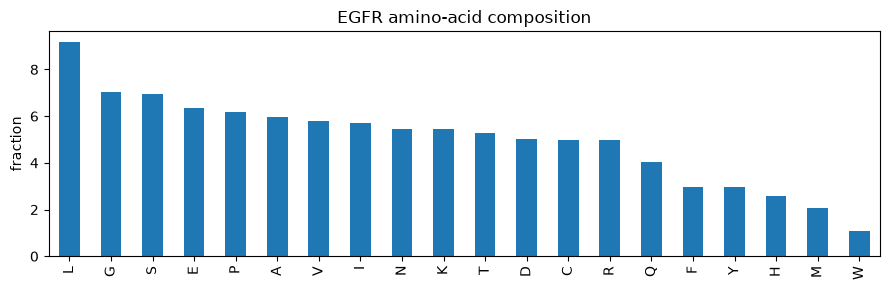

In [3]:
comp = pd.Series(pa.amino_acids_percent).sort_values(ascending=False)
comp.plot.bar(figsize=(9, 3), color="tab:blue")
plt.ylabel("fraction"); plt.title("EGFR amino-acid composition"); plt.tight_layout(); plt.show()

## 2. The kinase domain as an expression construct

In [4]:
kd_seq = str(egfr.seq[695:1022])          # residues 696-1022, a common construct for kinase assays
kd_pa = ProteinAnalysis(kd_seq)
print(f"construct 696-1022: {len(kd_seq)} aa, {kd_pa.molecular_weight()/1000:.1f} kDa, "
      f"pI {kd_pa.isoelectric_point():.2f}, ε280 {kd_pa.molar_extinction_coefficient()[0]}")
helix, turn, sheet = kd_pa.secondary_structure_fraction()
print(f"residue-propensity estimate: helix {helix:.2f}, turn {turn:.2f}, sheet {sheet:.2f}")

construct 696-1022: 327 aa, 37.3 kDa, pI 5.59, ε280 52370
residue-propensity estimate: helix 0.35, turn 0.25, sheet 0.37


`secondary_structure_fraction` simply counts residues that *tend* to form helix/turn/sheet; it is a
rough indicator, not a structure prediction.

## 3. Hydropathy profile

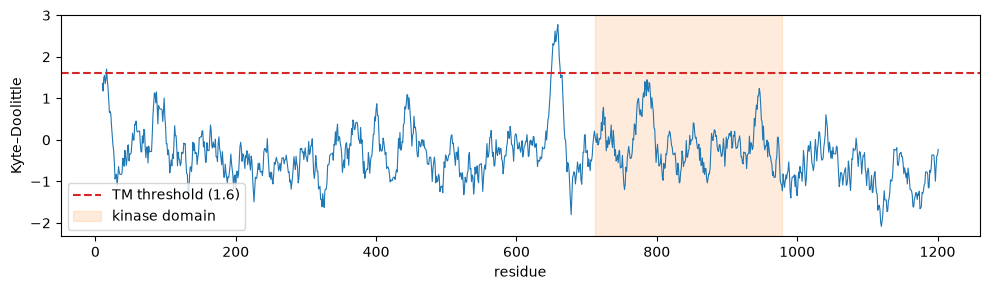

hydrophobic segments (window centres): [(16, 16), (650, 662)]


In [5]:
window = 19
profile = pa.protein_scale(kyte_doolittle, window)
x = np.arange(len(profile)) + window // 2 + 1
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(x, profile, lw=0.8)
ax.axhline(1.6, color="tab:red", ls="--", label="TM threshold (1.6)")
ax.axvspan(712, 979, color="tab:orange", alpha=0.15, label="kinase domain")
ax.set_xlabel("residue"); ax.set_ylabel("Kyte–Doolittle"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# group consecutive window centres above the threshold into segments
above = x[np.array(profile) > 1.6]
segments, start = [], None
for i, r in enumerate(above):
    if start is None:
        start = r
    if i == len(above) - 1 or above[i + 1] != r + 1:
        segments.append((int(start), int(r))); start = None
print("hydrophobic segments (window centres):", segments)

Kyte and Doolittle suggested that a 19-residue window averaging above ~1.6 marks a membrane-spanning
helix. Compare with the UniProt annotation (cached in `data/sequences/P00533_uniprot_features.json`):

In [6]:
import json
with open(f"{DATA_DIR}/sequences/P00533_uniprot_features.json") as fh:
    feats = json.load(fh)["features"]
for f in feats:
    if f["type"] in ("Signal", "Transmembrane", "Topological domain"):
        print(f"{f['type']:<19} {f['location']['start']['value']:>4}-{f['location']['end']['value']:<4} {f.get('description', '')}")

Signal                 1-24   
Topological domain    25-645  Extracellular
Transmembrane        646-668  Helical
Topological domain   669-1210 Cytoplasmic


The window-centre segments line up with the signal peptide (1–24) and the transmembrane helix (646–668).

## 4. A panel of drug targets

In [7]:
rows = []
for rec in SeqIO.parse(f"{DATA_DIR}/sequences/kinase_panel_full.fasta", "fasta"):
    s = str(rec.seq)
    p = ProteinAnalysis(s.replace("X", "").replace("U", "C"))
    rows.append({"protein": rec.id.split("|")[1], "length": len(s), "MW_kDa": p.molecular_weight() / 1000,
                 "pI": p.isoelectric_point(), "instability": p.instability_index(), "GRAVY": p.gravy()})
props = pd.DataFrame(rows).round(2).sort_values("MW_kDa", ascending=False)
props

,protein,length,MW_kDa,pI,instability,GRAVY
14,ALK_HUMAN,1620,176.44,6.67,51.12,-0.30
5,EGFR_DROME,1426,159.72,7.31,44.33,-0.46
13,MET_HUMAN,1390,155.54,7.02,42.61,-0.14
10,VGFR2_HUMAN,1356,151.53,5.60,45.34,-0.27
6,LET23_CAEEL,1323,150.51,6.45,44.45,-0.50
2,ERBB3_HUMAN,1342,148.10,6.11,49.61,-0.39
3,ERBB4_HUMAN,1308,146.81,5.98,45.83,-0.38
1,ERBB2_HUMAN,1255,137.91,5.58,56.13,-0.25
4,EGFR_MOUSE,1210,134.85,6.46,43.54,-0.32
0,EGFR_HUMAN,1210,134.28,6.26,44.59,-0.32


## 5. Motifs with regular expressions

The N-glycosylation sequon is **N-X-S/T** where X is not proline (PROSITE PS00001: `N-{P}-[ST]-{P}`).
A lookahead `(?=...)` finds overlapping matches.

In [8]:
sequon = re.compile(r"(?=(N[^P][ST][^P]))")
hits = [m.start() + 1 for m in sequon.finditer(str(egfr.seq))]
print(len(hits), "sequons at residues:", hits)
extracellular = [h for h in hits if 25 <= h <= 645]
print(len(extracellular), "of them lie in the extracellular region (25-645)")
annotated = sorted(f["location"]["start"]["value"] for f in feats if f["type"] == "Glycosylation")
print("UniProt-annotated N-glycosylation sites:", annotated)
print("extracellular sequons that are annotated as glycosylated:", sorted(set(extracellular) & set(annotated)))

15 sequons at residues: [128, 175, 196, 352, 361, 413, 444, 528, 568, 603, 623, 1043, 1044, 1094, 1148]
11 of them lie in the extracellular region (25-645)
UniProt-annotated N-glycosylation sites: [56, 73, 128, 175, 196, 352, 361, 413, 444, 528, 568, 603, 623]
extracellular sequons that are annotated as glycosylated: [128, 175, 196, 352, 361, 413, 444, 528, 568, 603, 623]


All 11 extracellular sequons are annotated glycosylation sites, but the 4 cytoplasmic ones are not:
N-glycosylation happens in the lumen of the ER and Golgi, so a sequon facing the cytoplasm is never
modified. UniProt also lists two "atypical" sites (N56, N73) that do not follow the sequon rule. Motif
matches are hypotheses; biological context decides.

## 6. Position-specific motifs with `Bio.motifs`

The glycine-rich loop ("G-loop", consensus **GxGxxG**) clamps ATP in every kinase. We take the aligned
G-loop from the MSA (Notebook 07) and build a motif: counts, consensus, and a position weight matrix.

In [9]:
msa = AlignIO.read(f"{DATA_DIR}/alignments/kinase_domains_famsa.aln", "clustal")
egfr_row = str(msa[0].seq)
start = egfr_row.find("GSGAFG")                     # EGFR's G-loop, residues 719-724
gloop = [Seq(str(rec.seq[start:start + 6])) for rec in msa]
for rec, g in zip(msa, gloop):
    print(f"{rec.id:<13} {g}")

EGFR_HUMAN    GSGAFG
ERBB2_HUMAN   GSGAFG
ERBB3_HUMAN   GSGVFG
ERBB4_HUMAN   GSGAFG
EGFR_MOUSE    GSGAFG
EGFR_DROME    GMGAFG
LET23_CAEEL   GAGAFG
ABL1_HUMAN    GGGQYG
SRC_HUMAN     GQGCFG
BRAF_HUMAN    GSGSFG
VGFR2_HUMAN   GRGAFG
BTK_HUMAN     GTGQFG
CDK2_HUMAN    GEGTYG
MET_HUMAN     GRGHFG
ALK_HUMAN     GHGAFG


In [10]:
m = motifs.create(gloop, alphabet="ACDEFGHIKLMNPQRSTVWY")
print("consensus:", m.consensus, "| degenerate-free consensus of conserved positions:",
      "".join(c if max(m.counts[a][i] for a in m.alphabet) == len(gloop) else "x"
              for i, c in enumerate(m.consensus)))
pd.DataFrame({a: m.counts[a] for a in "AGSCTFYQ"}).T

consensus: GSGAFG | degenerate-free consensus of conserved positions: GxGxxG


,0,1,2,3,4,5
A,0.0,1.0,0.0,8.0,0.0,0.0
G,15.0,1.0,15.0,0.0,0.0,15.0
S,0.0,6.0,0.0,1.0,0.0,0.0
C,0.0,0.0,0.0,1.0,0.0,0.0
T,0.0,1.0,0.0,1.0,0.0,0.0
F,0.0,0.0,0.0,0.0,13.0,0.0
Y,0.0,0.0,0.0,0.0,2.0,0.0
Q,0.0,1.0,0.0,2.0,0.0,0.0


### ✏️ Exercise 1

Compute the pI and molecular weight of EGFR's **extracellular region** (residues 25-645). Is it more acidic or
basic than the kinase construct?

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
ecd = ProteinAnalysis(str(egfr.seq[24:645]))
print(f"ECD: {ecd.molecular_weight()/1000:.1f} kDa, pI {ecd.isoelectric_point():.2f}  vs kinase construct pI {kd_pa.isoelectric_point():.2f}")
```

</details>

### ✏️ Exercise 2

Count Cys residues in each panel protein and add it as a column `n_Cys` to `props`.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
ncys = {rec.id.split("|")[1]: rec.seq.count("C")
        for rec in SeqIO.parse(f"{DATA_DIR}/sequences/kinase_panel_full.fasta", "fasta")}
props["n_Cys"] = props["protein"].map(ncys)
props.sort_values("n_Cys", ascending=False).head()
```

</details>

### ✏️ Exercise 3

Use a regular expression to find the **HRD** catalytic motif (`H[RF]D`, the "HRD" of the catalytic loop) in
EGFR, and check that it falls inside the kinase domain (712-979).

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for mt in re.finditer(r"H[RF]D", str(egfr.seq)):
    pos = mt.start() + 1
    print(mt.group(), "at", pos, "| inside kinase domain:", 712 <= pos <= 979)
```

</details>

## Key takeaways

- `ProteinAnalysis` gives MW, pI, ε280, instability, and GRAVY in one line each.
- Hydropathy plots reveal transmembrane helices and signal peptides.
- Regex finds motif *candidates*; `Bio.motifs` summarizes aligned motif instances.

**Next:** [10 · Protein structures with Bio.PDB](10_protein_structure_biopdb.ipynb).